In [19]:
import pandas as pd
import os
import nibabel as nib
import numpy as np
# from pytorch_msssim import ssim, ms_ssim
from skimage.metrics import structural_similarity as ssim
# psnr
from skimage.metrics import peak_signal_noise_ratio as psnr
import re
import matplotlib.pyplot as plt 
import torch
from tqdm import tqdm
import ants
from PIL import Image

In [20]:
csv_file = "/scratch/anirudhkaushik/ADNI1_Complete_DataSplits.csv"
df = pd.read_csv(csv_file)
df = df[df[f'fold_1'] == 'test'].reset_index(drop=True)

df['Acq Date'] = pd.to_datetime(df['Acq Date'])
df = df.sort_values(by=['Subject', 'Visit', 'Acq Date']).drop_duplicates(subset=['Subject', 'Visit'], keep='last')
# Grouping subjects
subject_groups = df.groupby('Subject').apply(lambda x: x.sort_values(by='Acq Date'))
subjects = list(subject_groups.index.levels[0])


In [21]:
# calculate ssim and ms_ssim    
def get_metrics(target_img, noder_img):
    target_img_data = target_img
    noder_img_data = noder_img

    # target_img_data = (target_img_data - target_img_data.min())/ (target_img_data.max() - target_img_data.min())
    # noder_img_data = (noder_img_data - noder_img_data.min())/ (noder_img_data.max() - noder_img_data.min())
    # target_img_data = target_img_data.astype(np.float32)
    # noder_img_data = noder_img_data.astype(np.float32)


    ssim_value = ssim(target_img_data, noder_img_data, data_range=1, multichannel=False)
    psnr_value = psnr(target_img_data, noder_img_data, data_range=1)
    return ssim_value, psnr_value

def load_nii(imgPath,padding = (128, 128, 128)):
    img_data = nib.load(imgPath).get_fdata()
    if img_data.ndim == 4:
        img_data = img_data.squeeze(0)
    img_data,_ = pad(img_data,shape=padding)
    img_data = preprocess_Normalizition(img_data)

    return img_data

def pad(array, shape):
    """
    Zero-pads an array to a given shape. Returns the padded array and crop slices.
    """
    if array.shape == tuple(shape):
        return array, ...

    padded = np.zeros(shape, dtype=array.dtype)
    offsets = [int((p - v) / 2) for p, v in zip(shape, array.shape)]
    slices = tuple([slice(offset, l + offset) for offset, l in zip(offsets, array.shape)])
    padded[slices] = array

    return padded, slices

def preprocess_Normalizition(img,method="min_max"):
    img=img.astype(np.float32)
    if method=="min_max":
        front_img=img[img>0]
        min_value=np.min(front_img)
        max_value=np.max(front_img)
        img=(img-min_value)/(max_value-min_value)
        img[img<0]=0.0
    elif method=="mean":
        front_img=img[img>0]
        mean_value=np.mean(front_img)
        std_value=np.std(front_img)
        img=(img-mean_value)/std_value
    return img

# Define function to calculate Dice score
def dice_score(pred, target):
    intersection = np.sum(pred * target)
    return (2.0 * intersection) / (np.sum(pred) + np.sum(target) + 1e-6)  # Add small epsilon to avoid division by zero

# Function to extract specific region from segmentation mask
def extract_region(seg_data, region_ids):
    """
    Extract binary mask for specific region(s)
    
    Args:
        seg_data: 3D numpy array of segmentation data
        region_ids: List of region IDs to extract
        
    Returns:
        Binary mask where the specified regions are 1, everything else is 0
    """
    mask = np.zeros_like(seg_data)
    for region_id in region_ids:
        mask[seg_data == region_id] = 1
    return mask

In [22]:
# Update your existing code with the following additions:
noder_dir = "/scratch/anirudhkaushik/NODER_result/"
all_noder_files = os.listdir(noder_dir)
synbadd_dir = "/scratch/anirudhkaushik/SYNBADD_Qualitative_1/SYNBADD_128_6_5e-05_0.0_2025-04-16_04-59-48_ADNI_all_longitudinal_FinalVAETransformer_Vanilla_Fold1/"
all_synbadd_files = os.listdir(synbadd_dir)
remind_dir = "/scratch/anirudhkaushik/interpolated_results/"
all_remind_files = os.listdir(remind_dir)
ssim_values = []
psnr_values = []

synbadd_ssim_values = []
synbadd_psnr_values = []

remind_ssim_values = []
remind_psnr_values = []

failed_files = 0

mask_dir = "/scratch/anirudhkaushik/ADNI_Resized_Registered_segs/"
all_mask_files = os.listdir(mask_dir)

# Define regions of interest and their corresponding IDs in the DKT atlas
regions = {
    'hippocampus': [17, 53],  # Left and right hippocampus
    'parahippocampal': [1016, 2016],  # Left and right parahippocampal gyrus
    'third_ventricle': [14]  # Third ventricle
}

# Initialize dictionaries to store Dice scores
noder_dice_scores = {region: [] for region in regions}
synbadd_dice_scores = {region: [] for region in regions}
remind_dice_scores = {region: [] for region in regions}

# Metrics Calculation

In [23]:

# for i, file in enumerate(tqdm(all_noder_files)):
#     if not file.endswith('.nii.gz'):
#         continue
    
#     image_id = re.search(r'S\d+_I\d+', file)
#     if not image_id:
#         continue
#     image_id = image_id.group(0)
    
#     # Find corresponding image in df File_Path using contains
#     try:
            
#         file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
        
#         # Find corresponding image in synbadd
#         synbadd_files = [f for f in all_synbadd_files if image_id in f]
#         if len(synbadd_files) < 2:
#             print(f"Skipping {image_id}: Missing SynBADD files")
#             continue

#         file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
#         target_img = load_nii(file_path)
#         remind_file = [f for f in all_remind_files if image_id in f][0]
        
#         for k in synbadd_files:
#             if "_synthetic.nii.gz" in k:
#                 synbadd_file_path = k
#             elif "_synthetic_field.nii.gz" in k:
#                 synbadd_field_path = k

#         # Find corresponding mask
#         mask_files = [f for f in all_mask_files if image_id in f]
#         seg_file = None
#         for k in mask_files:
#             if '_aparc.DKTatlas+aseg.deep_resized_IPL_padded.nii.gz' in k:
#                 seg_file = k
#                 break
        
#         if not seg_file:
#             print(f"Skipping {image_id}: Missing segmentation file")
#             continue

#         # Load images
#         target_img_data = load_nii(file_path)
#         noder_img_data = load_nii(os.path.join(noder_dir, file))
#         synbadd_img_data = load_nii(os.path.join(synbadd_dir, synbadd_file_path))
#         remind_img_data = load_nii(os.path.join(remind_dir, remind_file))
#         remind_img_data = remind_img_data.transpose(1,2,0)
        
#         # Calculate image quality metrics
#         ssim_value, psnr_value = get_metrics(target_img_data, noder_img_data)
#         synbadd_ssim_value, synbadd_psnr_value = get_metrics(target_img_data, synbadd_img_data)
#         remind_ssim_value, remind_psnr_value = get_metrics(target_img_data, remind_img_data)
        
#         ssim_values.append(ssim_value)
#         psnr_values.append(psnr_value)

#         synbadd_ssim_values.append(synbadd_ssim_value)
#         synbadd_psnr_values.append(synbadd_psnr_value)

#         remind_ssim_values.append(remind_ssim_value)
        
#         # print(f"Image ID: {image_id}, Noder SSIM: {ssim_value:.4f}, Noder PSNR: {psnr_value:.4f}, SynBADD SSIM: {synbadd_ssim_value:.4f}, SynBADD PSNR: {synbadd_psnr_value:.4f}, ReMiND SSIM: {remind_ssim_value:.4f}, ReMiND PSNR: {remind_psnr_value:.4f}")
        
#         # Visualization code from your original script can remain here

#         # plt.figure(figsize=(15, 5))
#         # plt.subplot(1,4, 1)
#         # plt.imshow(target_img_data[:, :, 64], cmap='gray')
#         # plt.axis('off')
#         # plt.title('Target Image')

#         # plt.subplot(1,4, 2)
#         # plt.imshow(noder_img_data[:, :, 64], cmap='gray')
#         # plt.axis('off')
#         # plt.title('NODER Image')

#         # plt.subplot(1,4, 3)
#         # plt.imshow(synbadd_img_data[:, :, 64], cmap='gray')
#         # plt.axis('off')
#         # plt.title('SynBADD Image')

#         # plt.subplot(1,4, 4)
#         # plt.imshow(remind_img_data[:, :, 64 ], cmap='gray')
#         # plt.axis('off')
#         # plt.title('ReMiND Image')

#         # plt.show()
#     except Exception as e:
#         failed_files += 1




In [24]:
# # print min, max and avg psnr and ssim
# print(f"Min PSNR Noder: {min(psnr_values)}")
# print(f"Max PSNR Noder: {max(psnr_values)}")
# print(f"Avg PSNR Noder: {np.mean(psnr_values)}")
# print(f"Min SSIM Noder: {min(ssim_values)}")
# print(f"Max SSIM Noder: {max(ssim_values)}")
# print(f"Avg SSIM Noder: {np.mean(ssim_values)}")
# # print min, max and avg psnr and ssim for synbadd
# print(f"Min PSNR SynBADD: {min(synbadd_psnr_values)}")
# print(f"Max PSNR SynBADD: {max(synbadd_psnr_values)}")
# print(f"Avg PSNR SynBADD: {np.mean(synbadd_psnr_values)}")
# print(f"Min SSIM SynBADD: {min(synbadd_ssim_values)}")
# print(f"Max SSIM SynBADD: {max(synbadd_ssim_values)}")
# print(f"Avg SSIM SynBADD: {np.mean(synbadd_ssim_values)}")
# # print min, max and avg psnr and ssim for remind
# print(f"Min PSNR ReMiND: {min(remind_psnr_values)}")
# print(f"Max PSNR ReMiND: {max(remind_psnr_values)}")
# print(f"Avg PSNR ReMiND: {np.mean(remind_psnr_values)}")
# print(f"Min SSIM ReMiND: {min(remind_ssim_values)}")
# print(f"Max SSIM ReMiND: {max(remind_ssim_values)}")
# print(f"Avg SSIM ReMiND: {np.mean(remind_ssim_values)}")

# # After processing all images, calculate average Dice scores
# print("\nAverage Dice Scores:")
# for region_name in regions:
#     avg_noder_dice = np.mean(noder_dice_scores[region_name])
#     avg_synbadd_dice = np.mean(synbadd_dice_scores[region_name])
#     print(f"{region_name.capitalize()}:")
#     print(f"  NODER: {avg_noder_dice:.4f}")
#     print(f"  SynBADD: {avg_synbadd_dice:.4f}")

# 3D Comparision

# Subtle Bad comparision

In [25]:
from matplotlib import cm

# Function to normalize and convert array to image
def array_to_image(array, colormap='coolwarm'):
    # Normalize to 0-1 range
    norm_array = (array - array.min()) / (array.max() - array.min())
    
    # Apply colormap
    colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)
    
    # Convert to RGB (remove alpha channel)
    return colored_array[:, :, :3]


/tmp/ipykernel_39767/2362139710.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


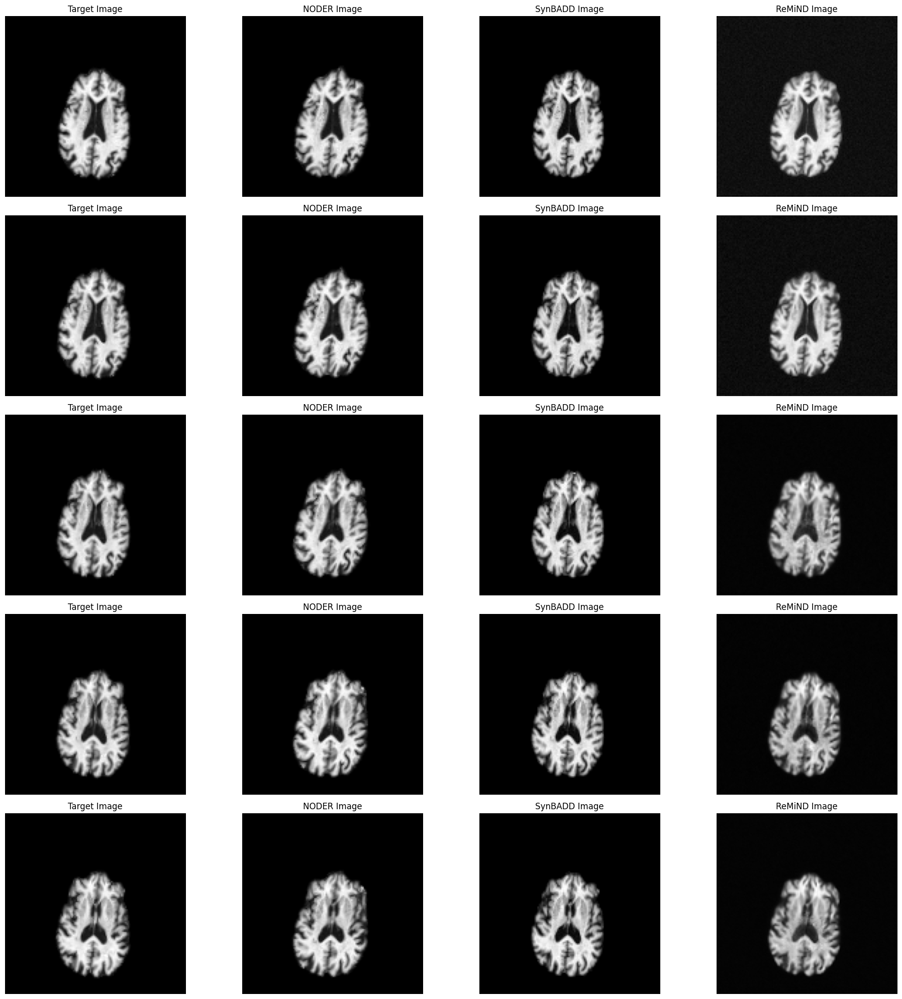

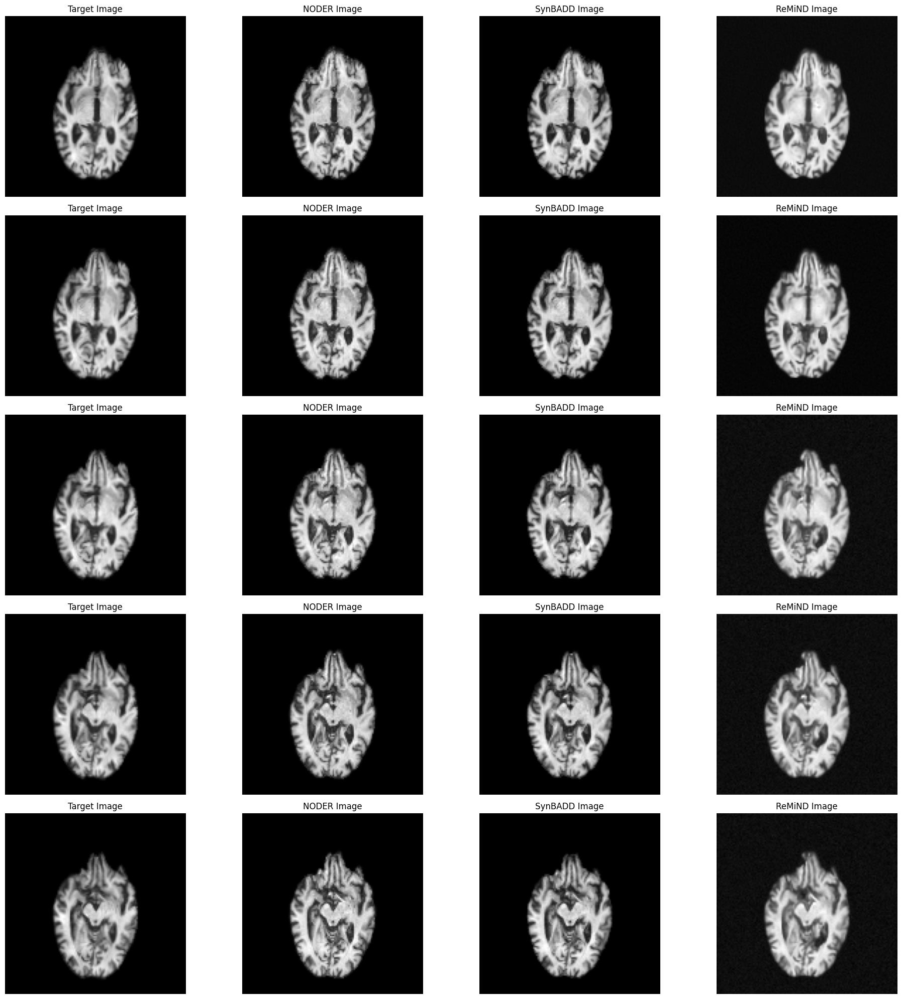

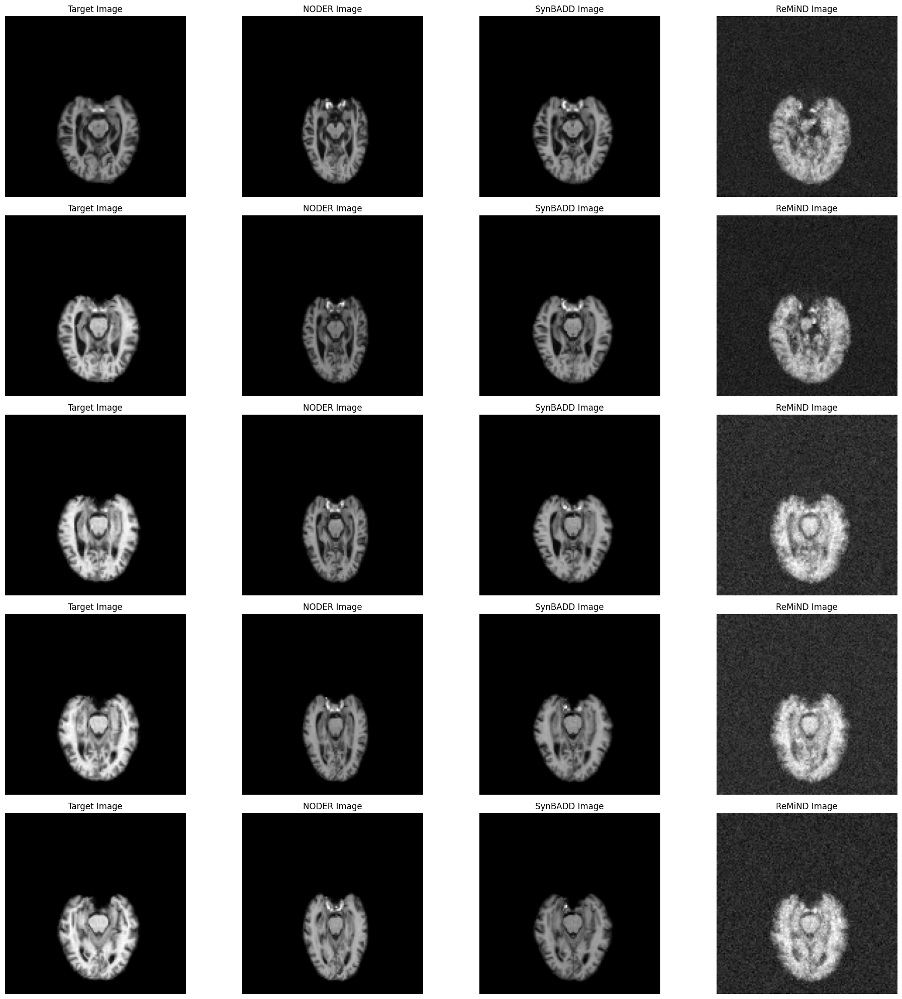

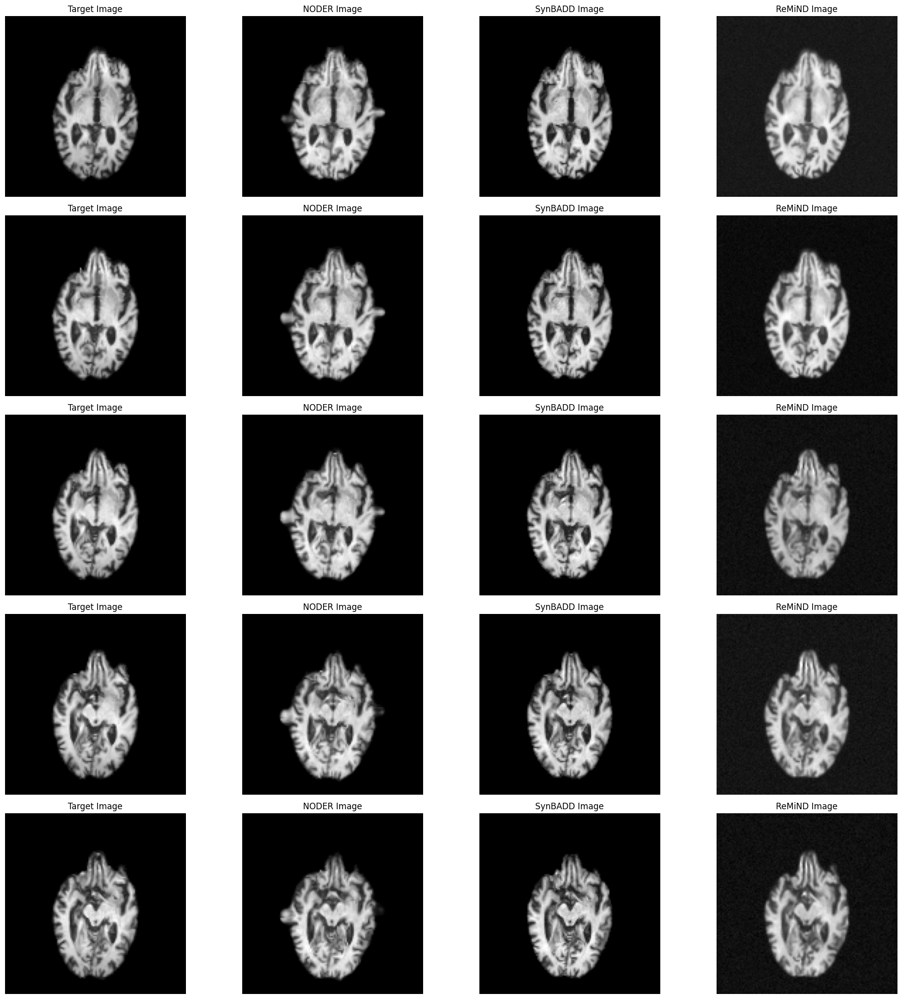

In [27]:
# display midslice -2 to midslice +2 for noder, remind and synbadd for selected image ids
image_id_list = ["S33710_I80689","S18956_I34141","S33081_I86630","S39424_I78876"]
for image_id in image_id_list:
    file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
    noder_file = [f for f in all_noder_files if image_id in f][0]
    # Find corresponding image in synbadd
    synbadd_files = [f for f in all_synbadd_files if image_id in f]
    if len(synbadd_files) < 2:
        print(f"Skipping {image_id}: Missing SynBADD files")
        continue

    file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
    target_img = load_nii(file_path)
    remind_file = [f for f in all_remind_files if image_id in f][0]

    for k in synbadd_files:
            if "_synthetic.nii.gz" in k:
                synbadd_file_path = k
            elif "_synthetic_field.nii.gz" in k:
                synbadd_field_path = k

    target_img_data = load_nii(file_path)
    noder_img_data = load_nii(os.path.join(noder_dir, noder_file))
    synbadd_img_data = load_nii(os.path.join(synbadd_dir, synbadd_file_path))
    remind_img_data = load_nii(os.path.join(remind_dir, remind_file))
    remind_img_data = remind_img_data.transpose(1,2,0)

    # display midslices from -2 to +2
    midslice = target_img_data.shape[2] // 2

    total_rows = len(range(-2, 3))
    row = 0
    col = 4
    plt.figure(figsize=(20, 20))
    for j in range(-2, 3):
        plt.subplot(total_rows, 4, row*col + 1 )
        plt.imshow(target_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('Target Image')

        # save just the image using PIL
        img = array_to_image(target_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_target_{midslice + j}.png")

        plt.subplot(total_rows, 4, row*col + 2)
        plt.imshow(noder_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('NODER Image')

        img = array_to_image(noder_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_noder_{midslice + j}.png")


        plt.subplot(total_rows, 4, row*col + 3)
        plt.imshow(synbadd_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('SynBADD Image')

        img = array_to_image(synbadd_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_synbadd_{midslice + j}.png")

        plt.subplot(total_rows, 4, row*col + 4)
        plt.imshow(remind_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('ReMiND Image')

        img = array_to_image(remind_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_remind_{midslice + j}.png")

        # set spacing 
        plt.subplots_adjust(wspace=0.1, hspace=0.1)
        plt.tight_layout()

        row += 1


    plt.show()
    
    

# Extreme Bad Cases

/tmp/ipykernel_39767/2362139710.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


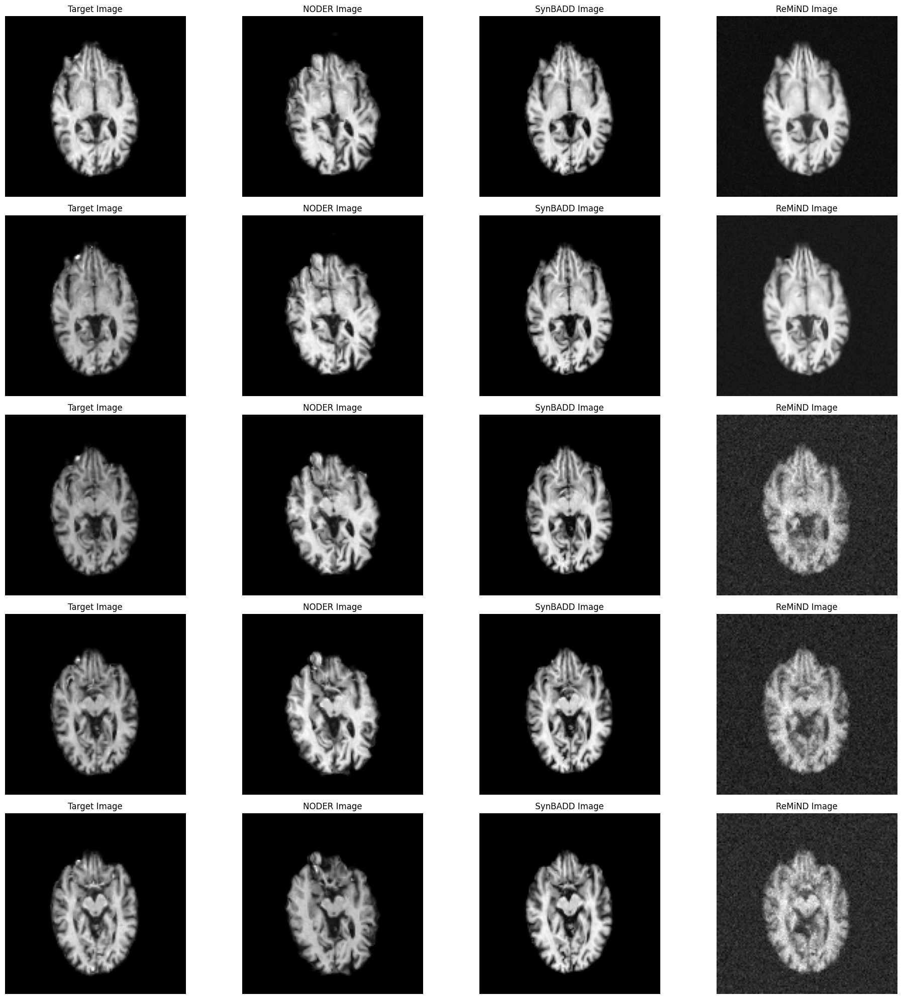

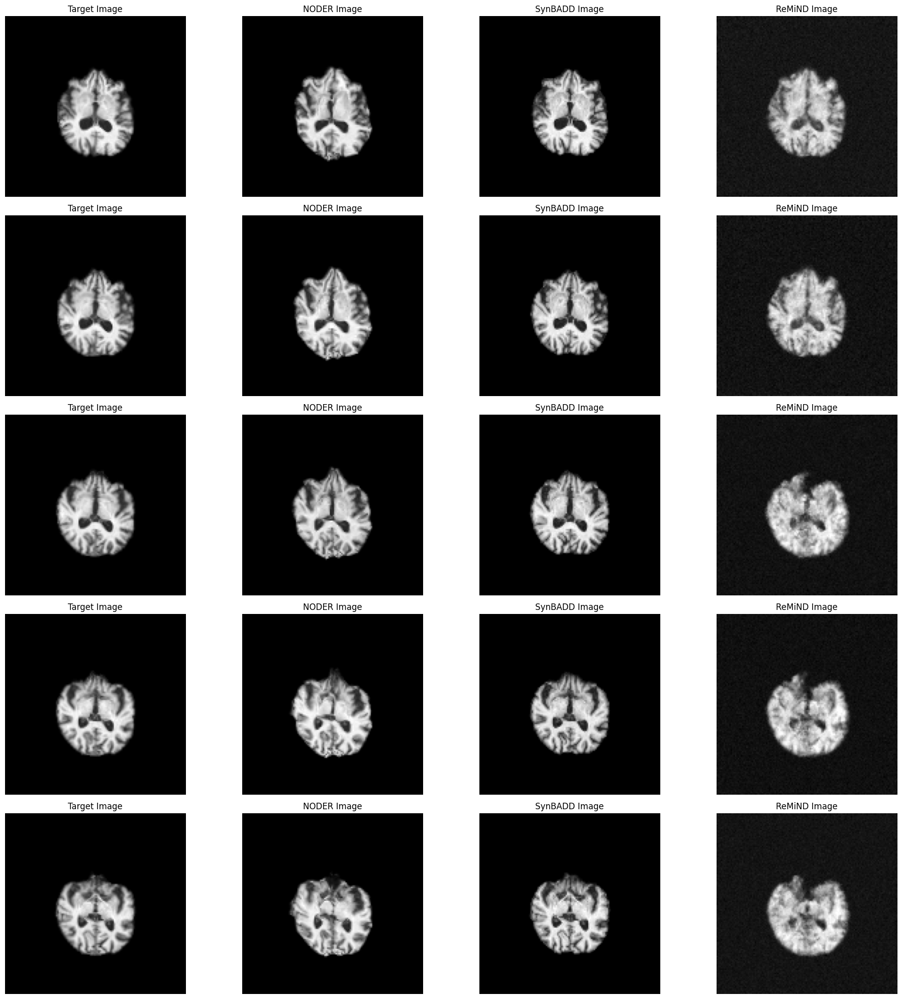

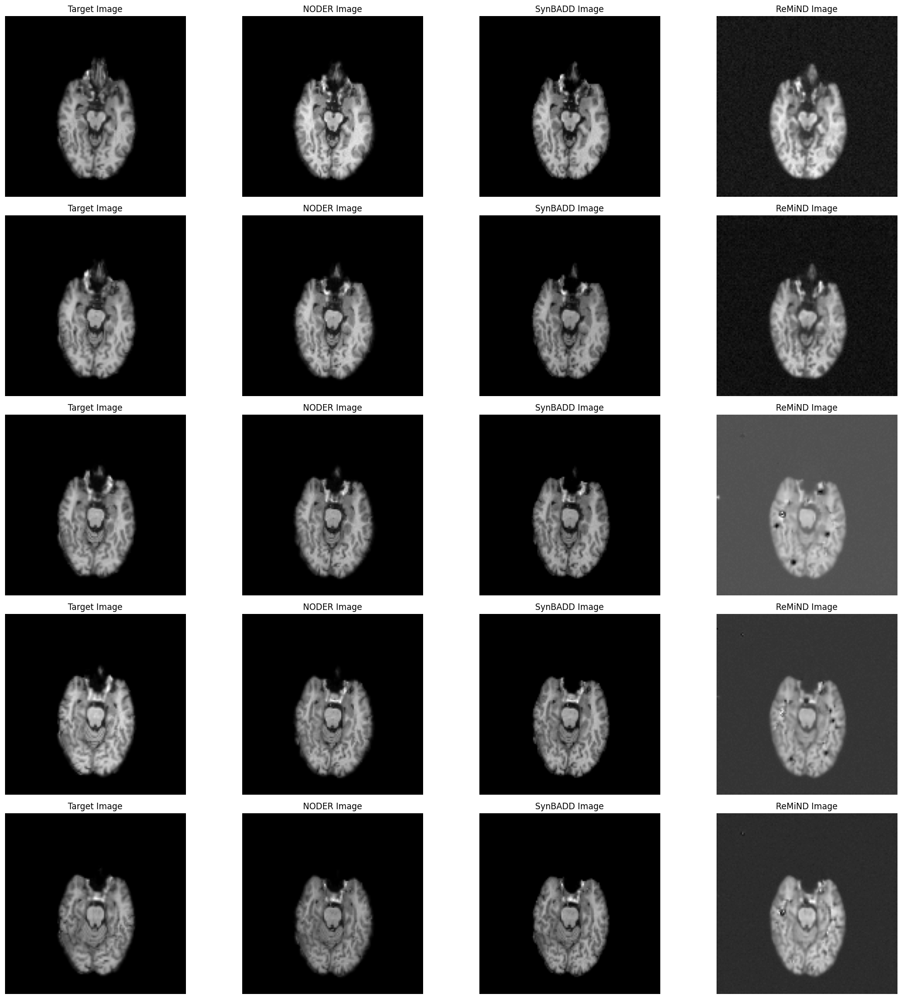

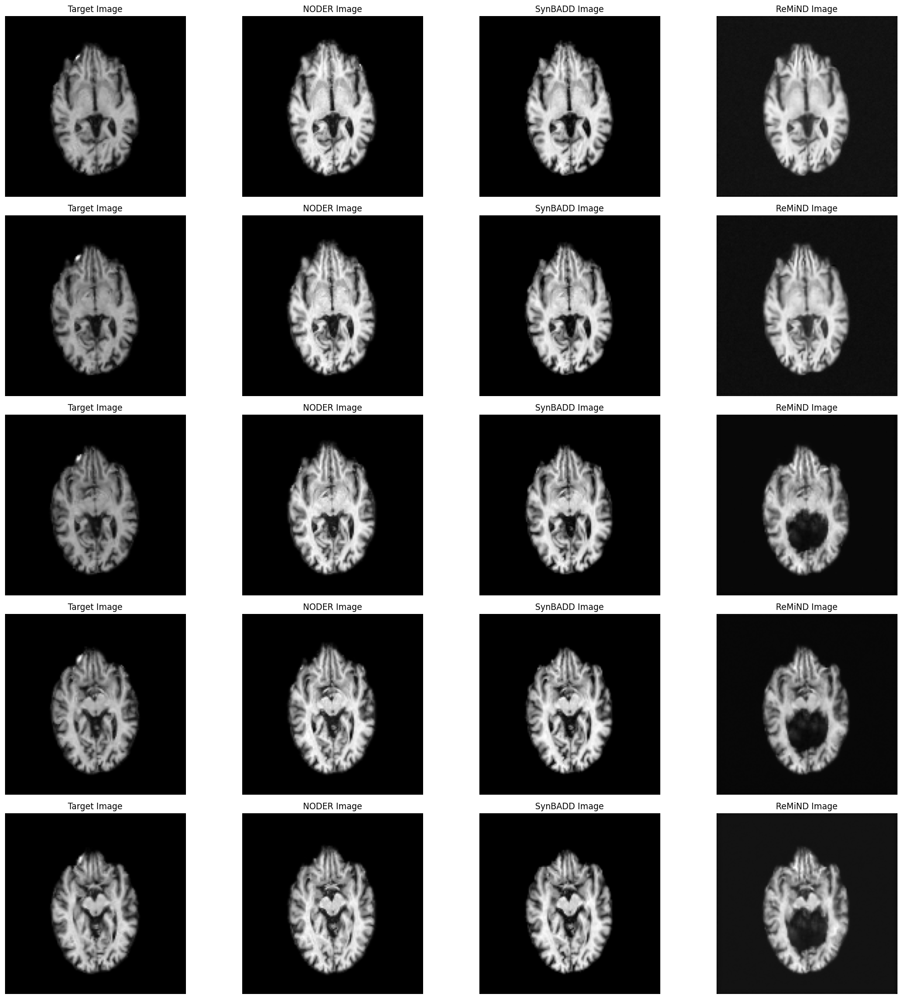

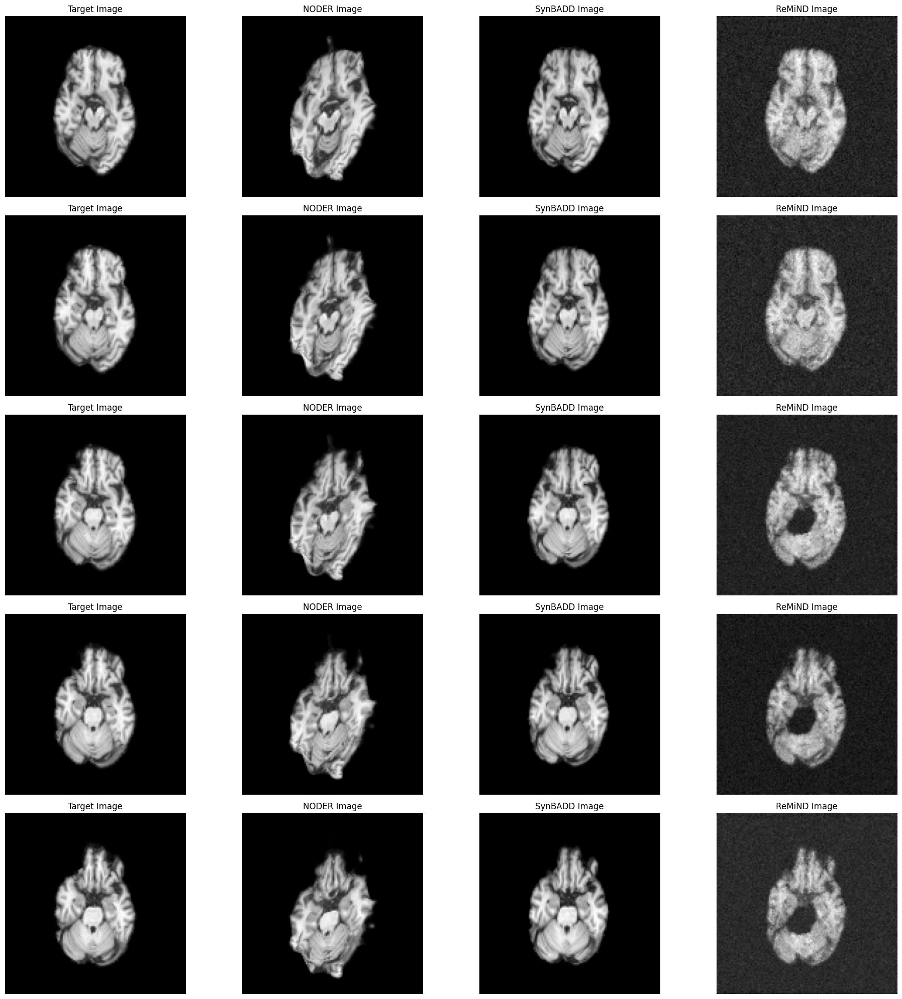

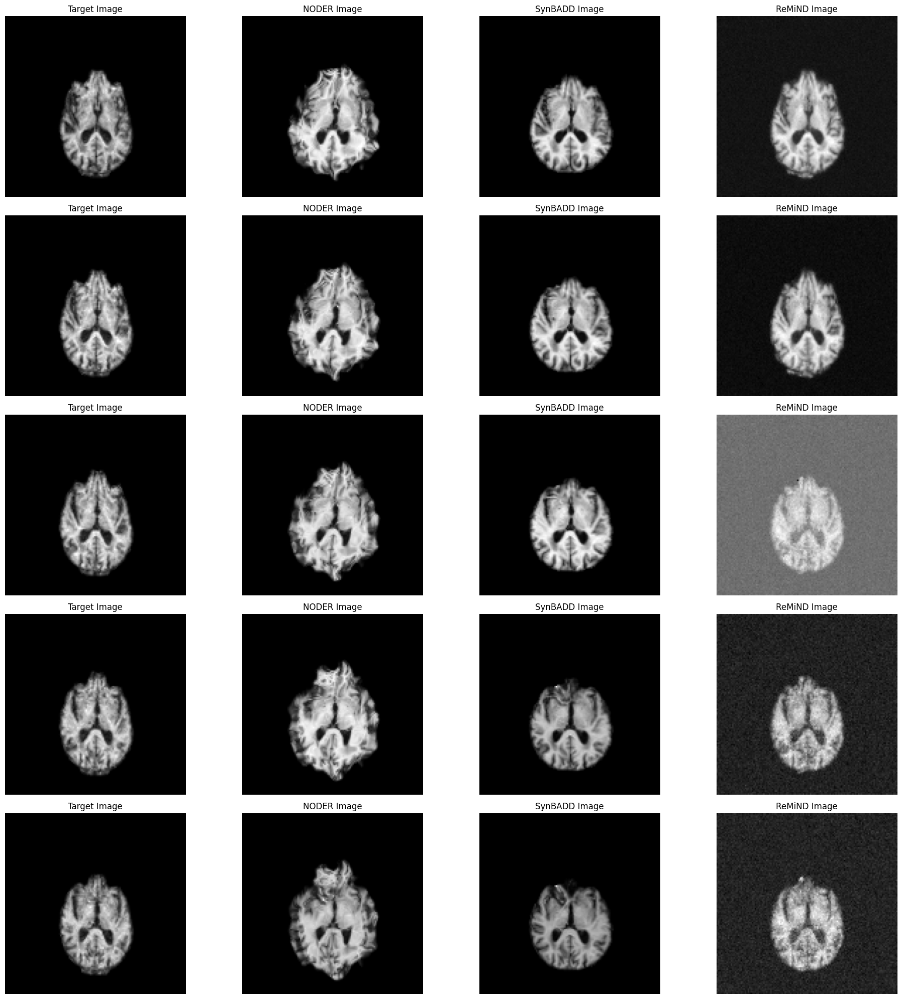

In [28]:
# display midslice -2 to midslice +2 for noder, remind and synbadd for selected image ids

image_id_list = ["S47041_I101425","S63312_I160680","S48653_I104531","S19508_I33469","S80537_I204870","S76920_I163371"]
for image_id in image_id_list:
    file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
    noder_file = [f for f in all_noder_files if image_id in f][0]
    # Find corresponding image in synbadd
    synbadd_files = [f for f in all_synbadd_files if image_id in f]
    if len(synbadd_files) < 2:
        print(f"Skipping {image_id}: Missing SynBADD files")
        continue

    file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
    target_img = load_nii(file_path)
    remind_file = [f for f in all_remind_files if image_id in f][0]

    for k in synbadd_files:
            if "_synthetic.nii.gz" in k:
                synbadd_file_path = k
            elif "_synthetic_field.nii.gz" in k:
                synbadd_field_path = k

    target_img_data = load_nii(file_path)
    noder_img_data = load_nii(os.path.join(noder_dir, noder_file))
    synbadd_img_data = load_nii(os.path.join(synbadd_dir, synbadd_file_path))
    remind_img_data = load_nii(os.path.join(remind_dir, remind_file))
    remind_img_data = remind_img_data.transpose(1,2,0)

    # display midslices from -2 to +2
    midslice = target_img_data.shape[2] // 2

    total_rows = len(range(-2, 3))
    row = 0
    col = 4
    plt.figure(figsize=(20, 20))
    for j in range(-2, 3):
        plt.subplot(total_rows, 4, row*col + 1 )
        plt.imshow(target_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('Target Image')

        # save just the image using PIL
        img = array_to_image(target_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_target_{midslice + j}.png")


        plt.subplot(total_rows, 4, row*col + 2)
        plt.imshow(noder_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('NODER Image')

        img = array_to_image(noder_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_noder_{midslice + j}.png")

        plt.subplot(total_rows, 4, row*col + 3)
        plt.imshow(synbadd_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('SynBADD Image')

        img = array_to_image(synbadd_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_synbadd_{midslice + j}.png")

        plt.subplot(total_rows, 4, row*col + 4)
        plt.imshow(remind_img_data[:, :, midslice + j], cmap='gray')
        plt.axis('off')
        plt.title('ReMiND Image')

        img = array_to_image(remind_img_data[:, :, midslice + j])
        img = Image.fromarray(img)
        img.save(f"./Final_qualitative_results/Slicewise/{image_id}_remind_{midslice + j}.png")

        # set spacing 
        plt.subplots_adjust(wspace=0.1, hspace=0.1)
        plt.tight_layout()

        row += 1


    plt.show()

# Extreme Case Diff Map

## 3D slider version

In [35]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import os

# Function to create a better visualization for all images
def visualize_all_comparisons(image_id, target_img, noder_img, synbadd_img, remind_img, 
                             diff_noder, diff_synbadd, diff_remind, slice_idx=64):
    """
    Comprehensive visualization of all images and difference maps
    
    Parameters:
    -----------
    image_id : str
        ID of the current image
    target_img, noder_img, synbadd_img, remind_img : numpy.ndarray
        The original and reconstructed images
    diff_noder, diff_synbadd, diff_remind : numpy.ndarray
        Difference maps between target and reconstructions
    slice_idx : int
        Slice index to visualize
    """
    # Create a figure with custom grid layout
    fig = plt.figure(figsize=(20, 12))
    gs = GridSpec(2, 4, figure=fig, width_ratios=[1, 1, 1, 1], height_ratios=[1, 1])
    
    # Determine min and max values for consistent colormaps
    vmin_img = min(
        np.percentile(target_img[:,:,slice_idx], 1),
        np.percentile(noder_img[:,:,slice_idx], 1),
        np.percentile(synbadd_img[:,:,slice_idx], 1),
        np.percentile(remind_img[:,:,slice_idx], 1)
    )
    vmax_img = max(
        np.percentile(target_img[:,:,slice_idx], 99),
        np.percentile(noder_img[:,:,slice_idx], 99),
        np.percentile(synbadd_img[:,:,slice_idx], 99),
        np.percentile(remind_img[:,:,slice_idx], 99)
    )
    
    # Determine difference map color limits
    vmax_diff = max(
        np.percentile(np.abs(diff_noder[:,:,slice_idx]), 95),
        np.percentile(np.abs(diff_synbadd[:,:,slice_idx]), 95),
        np.percentile(np.abs(diff_remind[:,:,slice_idx]), 95)
    )
    vmin_diff = -vmax_diff
    
    # Top row - Original Images
    ax_target = fig.add_subplot(gs[0, 0])
    im_target = ax_target.imshow(target_img[:,:,slice_idx], cmap='gray', 
                               vmin=vmin_img, vmax=vmax_img, origin='lower')
    
    # save as PIL image 
    

    ax_target.set_title('Target Image', fontsize=14)
    ax_target.set_axis_off()
    
    # Add NODER image and diff
    ax_noder = fig.add_subplot(gs[0, 1])
    im_noder = ax_noder.imshow(noder_img[:,:,slice_idx], cmap='gray', 
                             vmin=vmin_img, vmax=vmax_img, origin='lower')
    ax_noder.set_title('NODER Image', fontsize=14)
    ax_noder.set_axis_off()
    
    ax_noder_diff = fig.add_subplot(gs[1, 1])
    im_noder_diff = ax_noder_diff.imshow(diff_noder[:,:,slice_idx], cmap='seismic', 
                                       vmin=vmin_diff, vmax=vmax_diff, origin='lower')
    
    ax_noder_diff.set_title('NODER Difference', fontsize=14)
    ax_noder_diff.set_axis_off()
    
    # Add SynBADD image and diff
    ax_synbadd = fig.add_subplot(gs[0, 2])
    im_synbadd = ax_synbadd.imshow(synbadd_img[:,:,slice_idx], cmap='gray', 
                                 vmin=vmin_img, vmax=vmax_img, origin='lower')

    ax_synbadd.set_title('SynBADD Image', fontsize=14)
    ax_synbadd.set_axis_off()
    
    ax_synbadd_diff = fig.add_subplot(gs[1, 2])
    im_synbadd_diff = ax_synbadd_diff.imshow(diff_synbadd[:,:,slice_idx], cmap='seismic', 
                                           vmin=vmin_diff, vmax=vmax_diff, origin='lower')

    

    ax_synbadd_diff.set_title('SynBADD Difference', fontsize=14)
    ax_synbadd_diff.set_axis_off()
    
    # Add ReMIND image and diff
    ax_remind = fig.add_subplot(gs[0, 3])
    im_remind = ax_remind.imshow(remind_img[:,:,slice_idx], cmap='gray', 
                               vmin=vmin_img, vmax=vmax_img, origin='lower')

    

    ax_remind.set_title('ReMIND Image', fontsize=14)
    ax_remind.set_axis_off()
    
    ax_remind_diff = fig.add_subplot(gs[1, 3])
    im_remind_diff = ax_remind_diff.imshow(diff_remind[:,:,slice_idx], cmap='seismic', 
                                         vmin=vmin_diff, vmax=vmax_diff, origin='lower')

    

    
    
    ax_remind_diff.set_title('ReMIND Difference', fontsize=14)
    ax_remind_diff.set_axis_off()
    
    # Add Error Metrics
    ax_metrics = fig.add_subplot(gs[1, 0])
    ax_metrics.axis('off')

    img = array_to_image(target_img[:,:,slice_idx], colormap='gray')
    img = Image.fromarray(img)
    img.save(f"./Final_qualitative_results/DiffComparision/{image_id}_target_{slice_idx}.png")

    img = array_to_image(diff_noder[:,:,slice_idx], colormap='seismic')
    img = Image.fromarray(img)
    img.save(f"./Final_qualitative_results/DiffComparision/{image_id}_noder_diff_{slice_idx}.png")

    img = array_to_image(noder_img[:,:,slice_idx], colormap='gray')
    img = Image.fromarray(img)
    img.save(f"./Final_qualitative_results/DiffComparision/{image_id}_noder_{slice_idx}.png")

    img = array_to_image(synbadd_img[:,:,slice_idx], colormap='gray')
    img = Image.fromarray(img)
    img.save(f"./Final_qualitative_results/DiffComparision/{image_id}_synbadd_{slice_idx}.png")

    img = Image.fromarray((remind_img[:,:,slice_idx] * 255).astype(np.uint8))
    img = Image.fromarray(img)
    img.save(f"./Final_qualitative_results/DiffComparision/{image_id}_remind_{slice_idx}.png")

    #diff images

    img = array_to_image(diff_synbadd[:,:,slice_idx], colormap='seismic')
    img = Image.fromarray(img)
    img.save(f"./Final_qualitative_results/DiffComparision/{image_id}_synbadd_diff_{slice_idx}.png")

    
    img = array_to_image(diff_remind[:,:,slice_idx], colormap='seismic')
    img = Image.fromarray(img)
    img.save(f"./Final_qualitative_results/DiffComparision/{image_id}_remind_diff_{slice_idx}.png")
    
    # Calculate metrics
    mse_noder = np.mean(diff_noder**2)
    mse_synbadd = np.mean(diff_synbadd**2)
    mse_remind = np.mean(diff_remind**2)
    
    mae_noder = np.mean(np.abs(diff_noder))
    mae_synbadd = np.mean(np.abs(diff_synbadd))
    mae_remind = np.mean(np.abs(diff_remind))
    
    # Display metrics
    metrics_text = (
        f"Image ID: {image_id}\n"
        f"Slice: {slice_idx}\n\n"
        f"MSE Metrics:\n"
        f"NODER: {mse_noder:.6f}\n"
        f"SynBADD: {mse_synbadd:.6f}\n"
        f"ReMIND: {mse_remind:.6f}\n\n"
        f"MAE Metrics:\n"
        f"NODER: {mae_noder:.6f}\n"
        f"SynBADD: {mae_synbadd:.6f}\n"
        f"ReMIND: {mae_remind:.6f}"
    )
    ax_metrics.text(0.1, 0.5, metrics_text, fontsize=12, 
                   verticalalignment='center', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    # Add colorbars
    cbar_ax_img = fig.add_axes([0.02, 0.15, 0.01, 0.7])
    cbar_img = fig.colorbar(im_target, cax=cbar_ax_img)
    cbar_img.set_label('Image Intensity', fontsize=12)
    
    cbar_ax_diff = fig.add_axes([0.97, 0.15, 0.01, 0.7])
    cbar_diff = fig.colorbar(im_noder_diff, cax=cbar_ax_diff)
    cbar_diff.set_label('Difference', fontsize=12)
    
    plt.suptitle(f'Comparison of Reconstruction Methods - {image_id}', fontsize=16)
    
    return fig

def process_and_visualize_middle_slices(image_id_list):
    for image_id in image_id_list:
        try:
            # Find files
            file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
            noder_file = [f for f in all_noder_files if image_id in f][0]
            
            # Find corresponding image in synbadd
            synbadd_files = [f for f in all_synbadd_files if image_id in f]
            if len(synbadd_files) < 2:
                print(f"Skipping {image_id}: Missing SynBADD files")
                continue
                
            remind_file = [f for f in all_remind_files if image_id in f][0]
            
            # Find specific synbadd files
            for k in synbadd_files:
                if "_synthetic.nii.gz" in k:
                    synbadd_file_path = k
                elif "_synthetic_field.nii.gz" in k:
                    synbadd_field_path = k
            
            # Load all images
            target_img_data = load_nii(file_path)
            noder_img_data = load_nii(os.path.join(noder_dir, noder_file))
            synbadd_img_data = load_nii(os.path.join(synbadd_dir, synbadd_file_path))
            remind_img_data = load_nii(os.path.join(remind_dir, remind_file))
            remind_img_data = remind_img_data.transpose(1, 2, 0)
            
            # Calculate differences
            diff_noder = target_img_data - noder_img_data
            diff_synbadd = target_img_data - synbadd_img_data
            diff_remind = target_img_data - remind_img_data
            
            # Get middle slice
            n_slices = target_img_data.shape[2]
            middle_slice = n_slices // 2
            
            # print(f"\nVisualization for {image_id} - Middle slice ({middle_slice}):")
            
            # Visualize middle slice
            fig = visualize_all_comparisons(
                image_id, target_img_data, noder_img_data, synbadd_img_data, remind_img_data,
                diff_noder, diff_synbadd, diff_remind, middle_slice
            )
            plt.show()
            
        except Exception as e:
            print(f"Error processing {image_id}: {str(e)}")

In [36]:
from ipywidgets import interact, IntSlider

def process_and_visualize(image_id_list):
    for image_id in image_id_list:
        try:
            # Find files
            file_path = df[df['File_Path'].str.contains(image_id)]['File_Path'].values[0]
            noder_file = [f for f in all_noder_files if image_id in f][0]
            
            # Find corresponding image in synbadd
            synbadd_files = [f for f in all_synbadd_files if image_id in f]
            if len(synbadd_files) < 2:
                print(f"Skipping {image_id}: Missing SynBADD files")
                continue
                
            remind_file = [f for f in all_remind_files if image_id in f][0]
            
            # Find specific synbadd files
            for k in synbadd_files:
                if "_synthetic.nii.gz" in k:
                    synbadd_file_path = k
                elif "_synthetic_field.nii.gz" in k:
                    synbadd_field_path = k
            
            # Load all images
            target_img_data = load_nii(file_path)
            noder_img_data = load_nii(os.path.join(noder_dir, noder_file))
            synbadd_img_data = load_nii(os.path.join(synbadd_dir, synbadd_file_path))
            remind_img_data = load_nii(os.path.join(remind_dir, remind_file))
            remind_img_data = remind_img_data.transpose(1, 2, 0)
            
            # Calculate differences
            diff_noder = target_img_data - noder_img_data
            diff_synbadd = target_img_data - synbadd_img_data
            diff_remind = target_img_data - remind_img_data
            
            # Get number of slices
            n_slices = target_img_data.shape[2]
            middle_slice = n_slices // 2
            
            # Create an interactive slider function for this dataset
            def view_slice(slice_idx=middle_slice):
                fig = visualize_all_comparisons(
                    image_id, target_img_data, noder_img_data, synbadd_img_data, remind_img_data,
                    diff_noder, diff_synbadd, diff_remind, slice_idx
                )
                plt.show()
            
            # Create interactive widget
            slider = IntSlider(min=0, max=n_slices-1, value=middle_slice, 
                             description=f'Slice ({image_id}):',
                             continuous_update=False, layout={'width': '500px'})
            
            print(f"\n\nVisualization for {image_id} - Use slider to navigate slices:")
            interact(view_slice, slice_idx=slider)
            
        except Exception as e:
            print(f"Error processing {image_id}: {str(e)}")


In [38]:

# # Main loop through image IDs
# image_id_list = ["S19508_I33469", "S80537_I204870", "S76920_I163371"]

# # For interactive slider to navigate slices

# # Run the visualization
# process_and_visualize(image_id_list)

# # Uncomment this if you want the static version instead
# # process_and_visualize_static(image_id_list)

## Only Middle slice visualization

# Extreme bad cases

/tmp/ipykernel_39767/2362139710.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


Error processing S19508_I33469: expected string or buffer
Error processing S80537_I204870: expected string or buffer
Error processing S76920_I163371: expected string or buffer


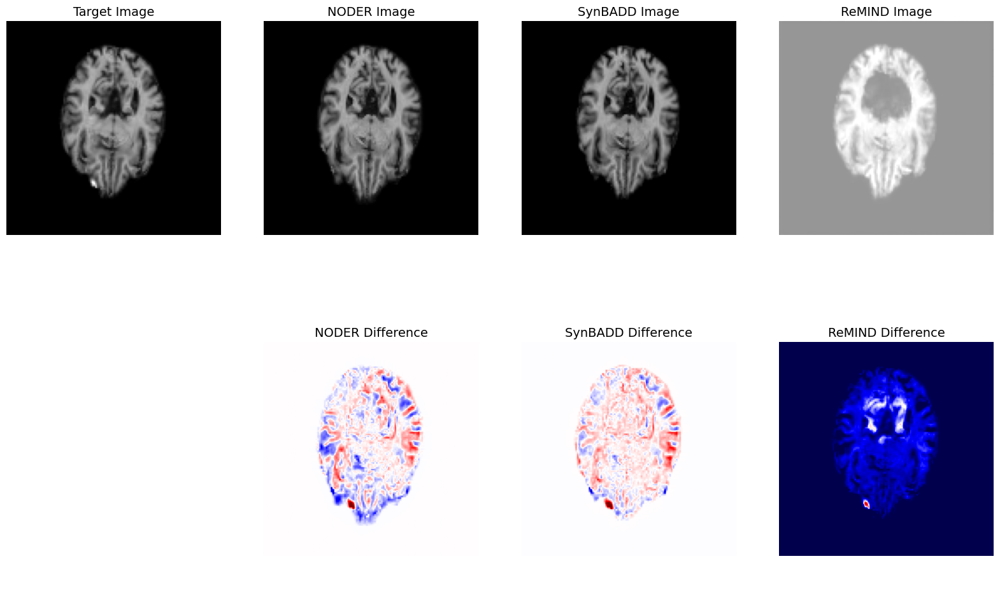

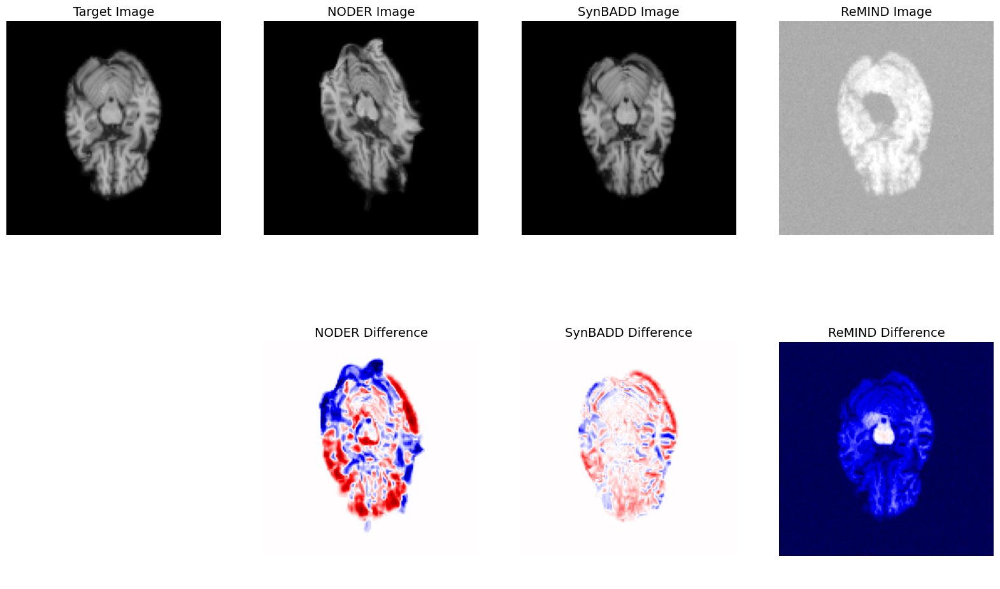

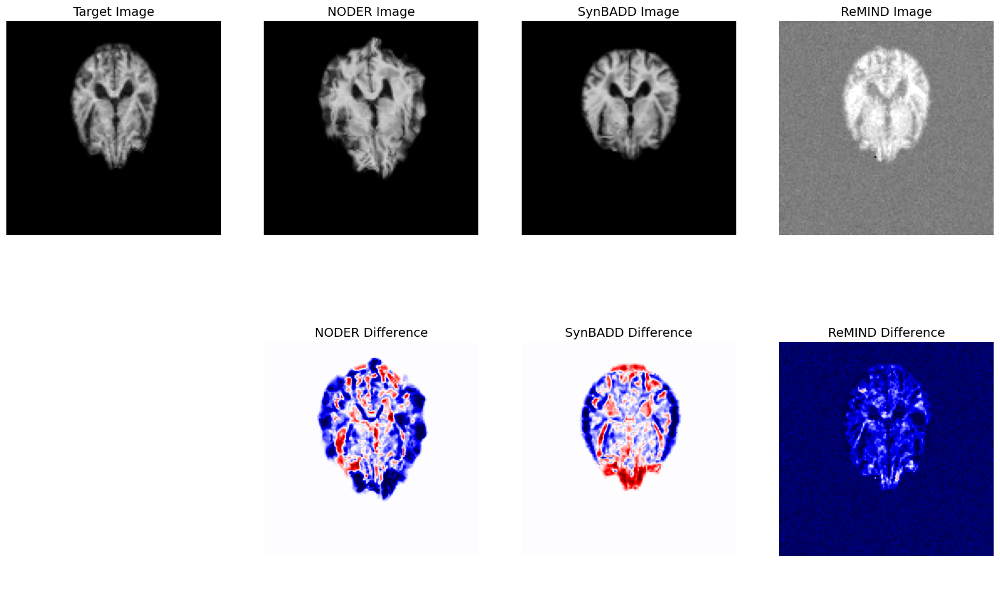

In [39]:
# Main loop through image IDs
image_id_list = ["S19508_I33469", "S80537_I204870", "S76920_I163371"]


# Run the visualization with middle slices only
process_and_visualize_middle_slices(image_id_list)

# Subtle Bad Cases

/tmp/ipykernel_39767/2362139710.py:9: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  colored_array = (cm.get_cmap(colormap)(norm_array) * 255).astype(np.uint8)


Error processing S33710_I80689: expected string or buffer
Error processing S18956_I34141: expected string or buffer
Error processing S33081_I86630: expected string or buffer
Error processing S39424_I78876: expected string or buffer


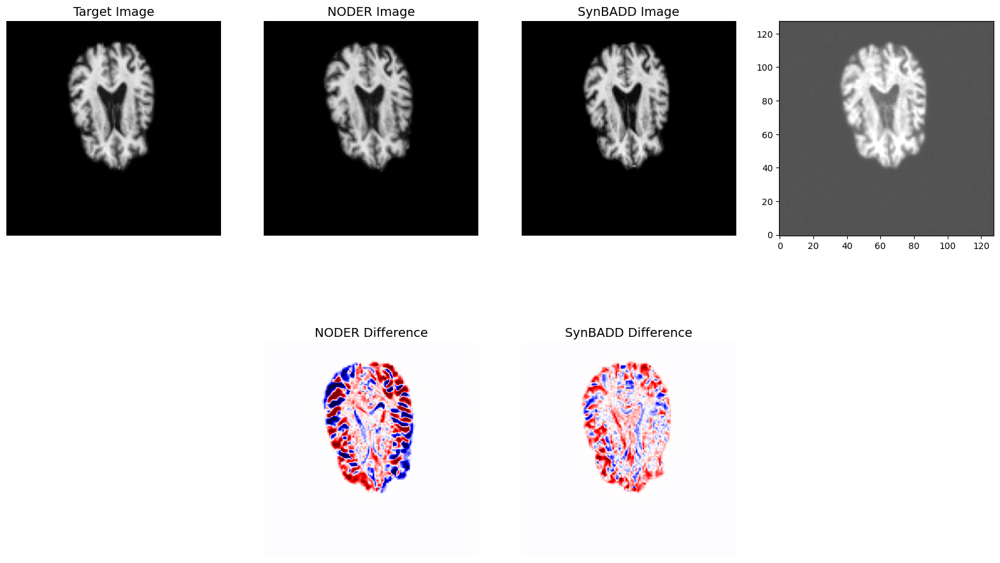

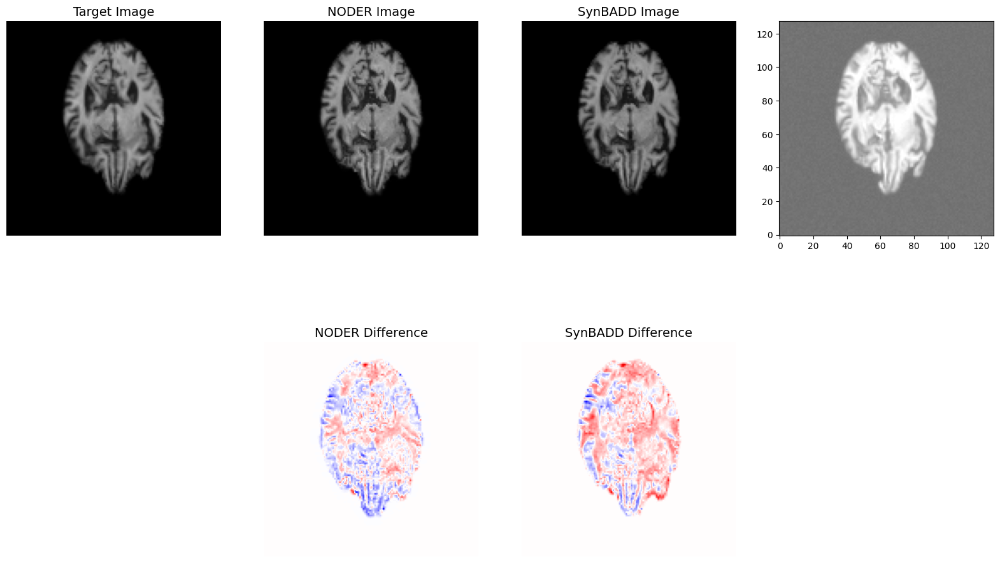

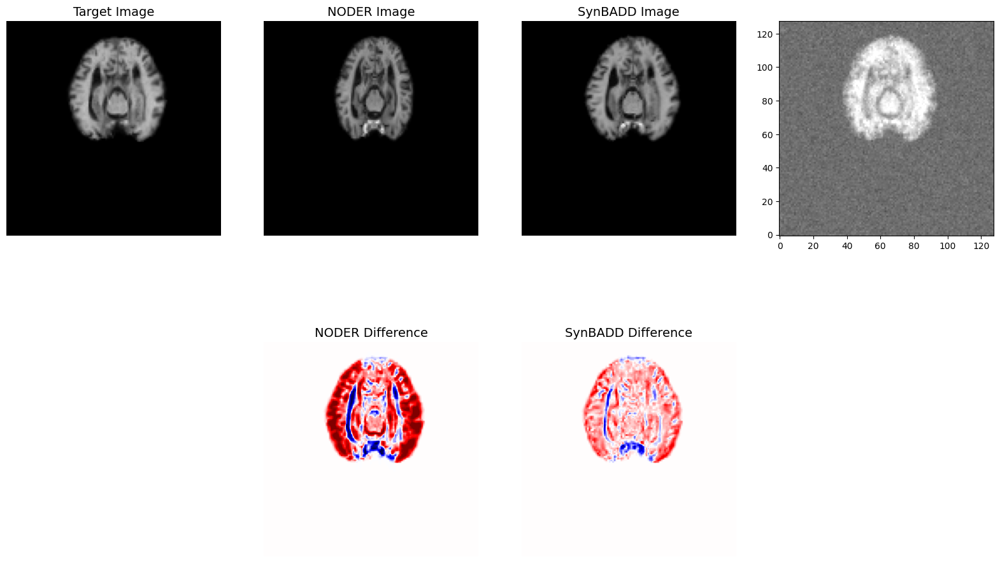

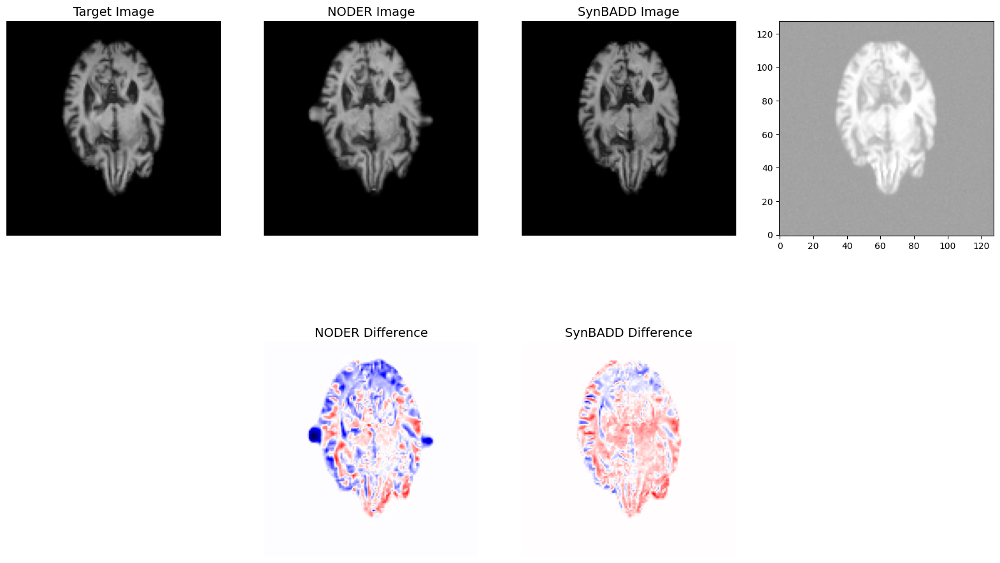

In [34]:

# Main loop through image IDs
image_id_list = ["S33710_I80689","S18956_I34141","S33081_I86630","S39424_I78876"]


# Run the visualization with middle slices only
process_and_visualize_middle_slices(image_id_list)